In [25]:
%matplotlib inline
import geopandas as gpd
import matplotlib.pyplot as plt

In [6]:
dat_path = '../dat/gis'
gdb_name = 'Consolidated_Cutblocks_2015.gdb'

In [7]:
gdf = gpd.read_file('%s/%s' % (dat_path, gdb_name))

In [8]:
gdf.columns

Index(['Opening_ID', 'Disturbance_Start_Date', 'Disturbance_End_Date',
       'Data_Source', 'Notes', 'tsa_num', 'Shape_Length', 'Shape_Area',
       'source_id', 'HARV_YEAR', 'geometry'],
      dtype='object')

In [9]:
gdf.head()

,Opening_ID,Disturbance_Start_Date,Disturbance_End_Date,Data_Source,Notes,tsa_num,Shape_Length,Shape_Area,source_id,HARV_YEAR,geometry
0,-714260000,1987-09-01T00:00:00,1986-01-01T00:00:00,VRI,"VRI polygons, linked to Results list",01,4074.324244,496252.419265,0,0,"(POLYGON ((1565287.734 636395.846, 1565295.459..."
1,-713800000,1984-10-01T00:00:00,1984-05-01T00:00:00,VRI,"VRI polygons, linked to Results list",01,3893.118120,754202.656704,0,0,"(POLYGON ((1564312.04 636179.018, 1564324.259 ..."
2,-712050000,1983-09-01T00:00:00,1983-10-01T00:00:00,VRI,"VRI polygons, linked to Results list",01,3805.672132,465544.116612,0,0,"(POLYGON ((1564599.042 635389.532, 1564672.997..."
3,-712040000,1985-07-01T00:00:00,1987-08-01T00:00:00,VRI,"VRI polygons, linked to Results list",01,3004.468003,443085.400997,0,0,"(POLYGON ((1566510.504 636035.411, 1566533.819..."
4,-712030000,1985-11-01T00:00:00,1987-09-01T00:00:00,VRI,"VRI polygons, linked to Results list",01,2780.640305,270045.873882,0,0,"(POLYGON ((1565745.47 636812.858, 1565690.989 ..."


In [10]:
len(gdf)

606554

In [100]:
gdf.area.min(), gdf.area.max() 

(9.9999999022111296e-06, 28509595.908969443)

In [105]:
gdf[gdf.Opening_ID == -745260000]

,Opening_ID,Disturbance_Start_Date,Disturbance_End_Date,Data_Source,Notes,tsa_num,Shape_Length,Shape_Area,source_id,HARV_YEAR,geometry,area
182536,-745260000,1993-12-02T00:00:00,1994-02-01T00:00:00,RESULTS,,17,1044.245026,8304.643931,0,0,"(POLYGON ((1369099.775 958053.165, 1369094.01 ...",0.830464
182537,-745260000,1993-12-02T00:00:00,1994-02-01T00:00:00,VRI,"VRI polygons, got attributes from OP",17,1724.362174,132745.970002,0,0,"(POLYGON ((1368453.422 957817.159, 1368462.699...",13.274597
182538,-745260000,1993-12-02T00:00:00,1994-02-01T00:00:00,VRI,"VRI polygons, got attributes from OP",17,1239.112069,24019.227472,0,0,"(POLYGON ((1368960 958253.929, 1368968.05 9582...",2.401923
182539,-745260000,1993-12-02T00:00:00,1994-02-01T00:00:00,VRI,"VRI polygons, got attributes from OP",17,1532.983349,33278.553249,0,0,"(POLYGON ((1368417.694 958566.916, 1368464.852...",3.327855
182540,-745260000,1993-12-02T00:00:00,1994-02-01T00:00:00,VRI,"VRI polygons, linked to Results list",17,3398.106085,480393.355809,0,0,"(POLYGON ((1368544.06 958447.24, 1368597.44 95...",48.039336


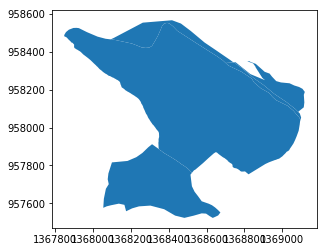

In [95]:
gdf[gdf.Opening_ID == -745260000].geometry.plot()

(1.0, 100.0)

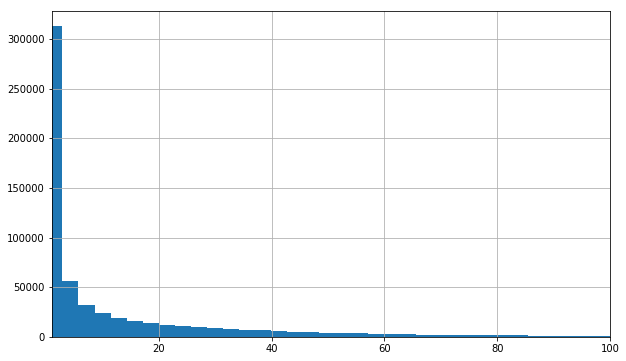

In [115]:
fig, ax = plt.subplots(figsize=(10, 6))
s = gdf[gdf.area > 1.].area * 0.0001
s.hist(bins=1000, ax=ax)
ax.set_xlim(1., 100.)

In [122]:
gdf.tsa_num.unique()

array(['01', '02', '03', '04', '05', '07', '08', '09', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23',
       '24dpg', '24dja', '24dva', '25', '26', '27', '29', '30', '31', '33',
       '37', '38', '39', '40', '41', '43', '44', '45'], dtype=object)

In [123]:
gdfg = gdf[gdf.tsa_num == '02'].groupby('Opening_ID')

In [124]:
gdfg.Shape_Area.sum().mean()

345071.69958085142

In [151]:
gdf_tsa02 = gpd.read_file('../dat/shp/tsa02.shp')

In [155]:
gdf_tsa02.area.mean()

147694.54609252882

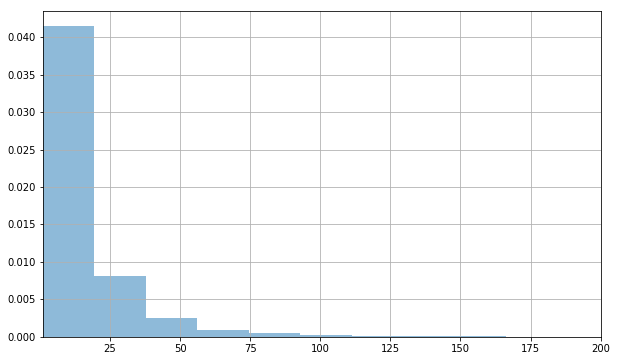

In [170]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(1., 200.)

s = gdf_tsa02.area.loc[lambda x: x>10000.].loc[lambda x: x<10000000.] * 0.0001
s.hist(bins=50, ax=ax, normed=True, alpha=0.5, label='TSA 02 polygons')

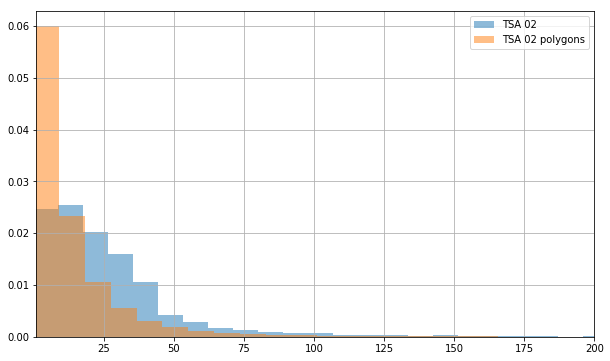

In [174]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(1., 200.)

gdfg = gdf[gdf.tsa_num == '02'].groupby('Opening_ID')
s = gdfg.Shape_Area.sum() * 0.0001
s = s.loc[lambda x: x>0.].loc[lambda x: x<1000.]
s.hist(bins=50, ax=ax, normed=True, alpha=0.5, label='TSA 02')

#gdfg = gdf[gdf.tsa_num != ''].groupby('Opening_ID')
#s = gdfg.Shape_Area.sum() * 0.0001
#s = s.loc[lambda x: x>0.].loc[lambda x: x<1000.]
#s.hist(bins=110, ax=ax, normed=True, alpha=0.5, label='All TSAs')

s = gdf_tsa02.area * 0.0001
s = s.loc[lambda x: x>0.].loc[lambda x: x<1000.]
s.hist(bins=100, ax=ax, normed=True, alpha=0.5, label='TSA 02 polygons')

ax.legend()


In [92]:
gdfg.Shape_Area.count()

Opening_ID
-1467960000    1
-985650000     1
-880690000     1
-745400000     1
-745370000     1
-745360000     1
-745350000     1
-745340000     1
-745330000     1
-745320000     1
-745310000     1
-745300000     1
-745290000     1
-745280000     3
-745260000     4
-745250000     1
-745240000     1
-745230000     1
-745210000     2
-745200000     2
-745180000     1
-745170000     4
-745160000     1
-745150000     1
-745140000     1
-745130000     1
-745020000     1
-745010000     2
-745000000     2
-744990000     1
              ..
 179710000     1
 180140000     1
 199650000     1
 204190000     1
 303740000     1
 308350000     1
 326740000     1
 500081116     1
 500081122     2
 500081559     1
 500082063     1
 500082066     1
 500082078     1
 500082629     1
 548660000     1
 552270000     1
 553630000     1
 580600000     1
 580640000     2
 580660000     1
 580680000     1
 580710000     1
 637220000     1
 637230000     1
 637260000     2
 638230000     1
 638260000     1
 64